Loading I-JEPA ViT-H/14...


config.json:   0%|          | 0.00/497 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

Model loaded!



100%|██████████| 169M/169M [33:04<00:00, 85.2kB/s]


Embedding 200 images...
  50/200 (353s)
  100/200 (692s)
  150/200 (1022s)
  200/200 (1364s)

Embeddings ready. Mean cosine sim: 0.6812
Time: 1364s

STANDARD MODEL
Survivors: 200/200, ρ = 0.9869

BAYESIAN MODEL v3 (relative evidence)
Survivors: 200/200, ρ = 0.9889
Confidence: min=0.0000, max=1.0000, mean=0.5680, spread=1.0000
Confidence-Decay ρ = -0.0267


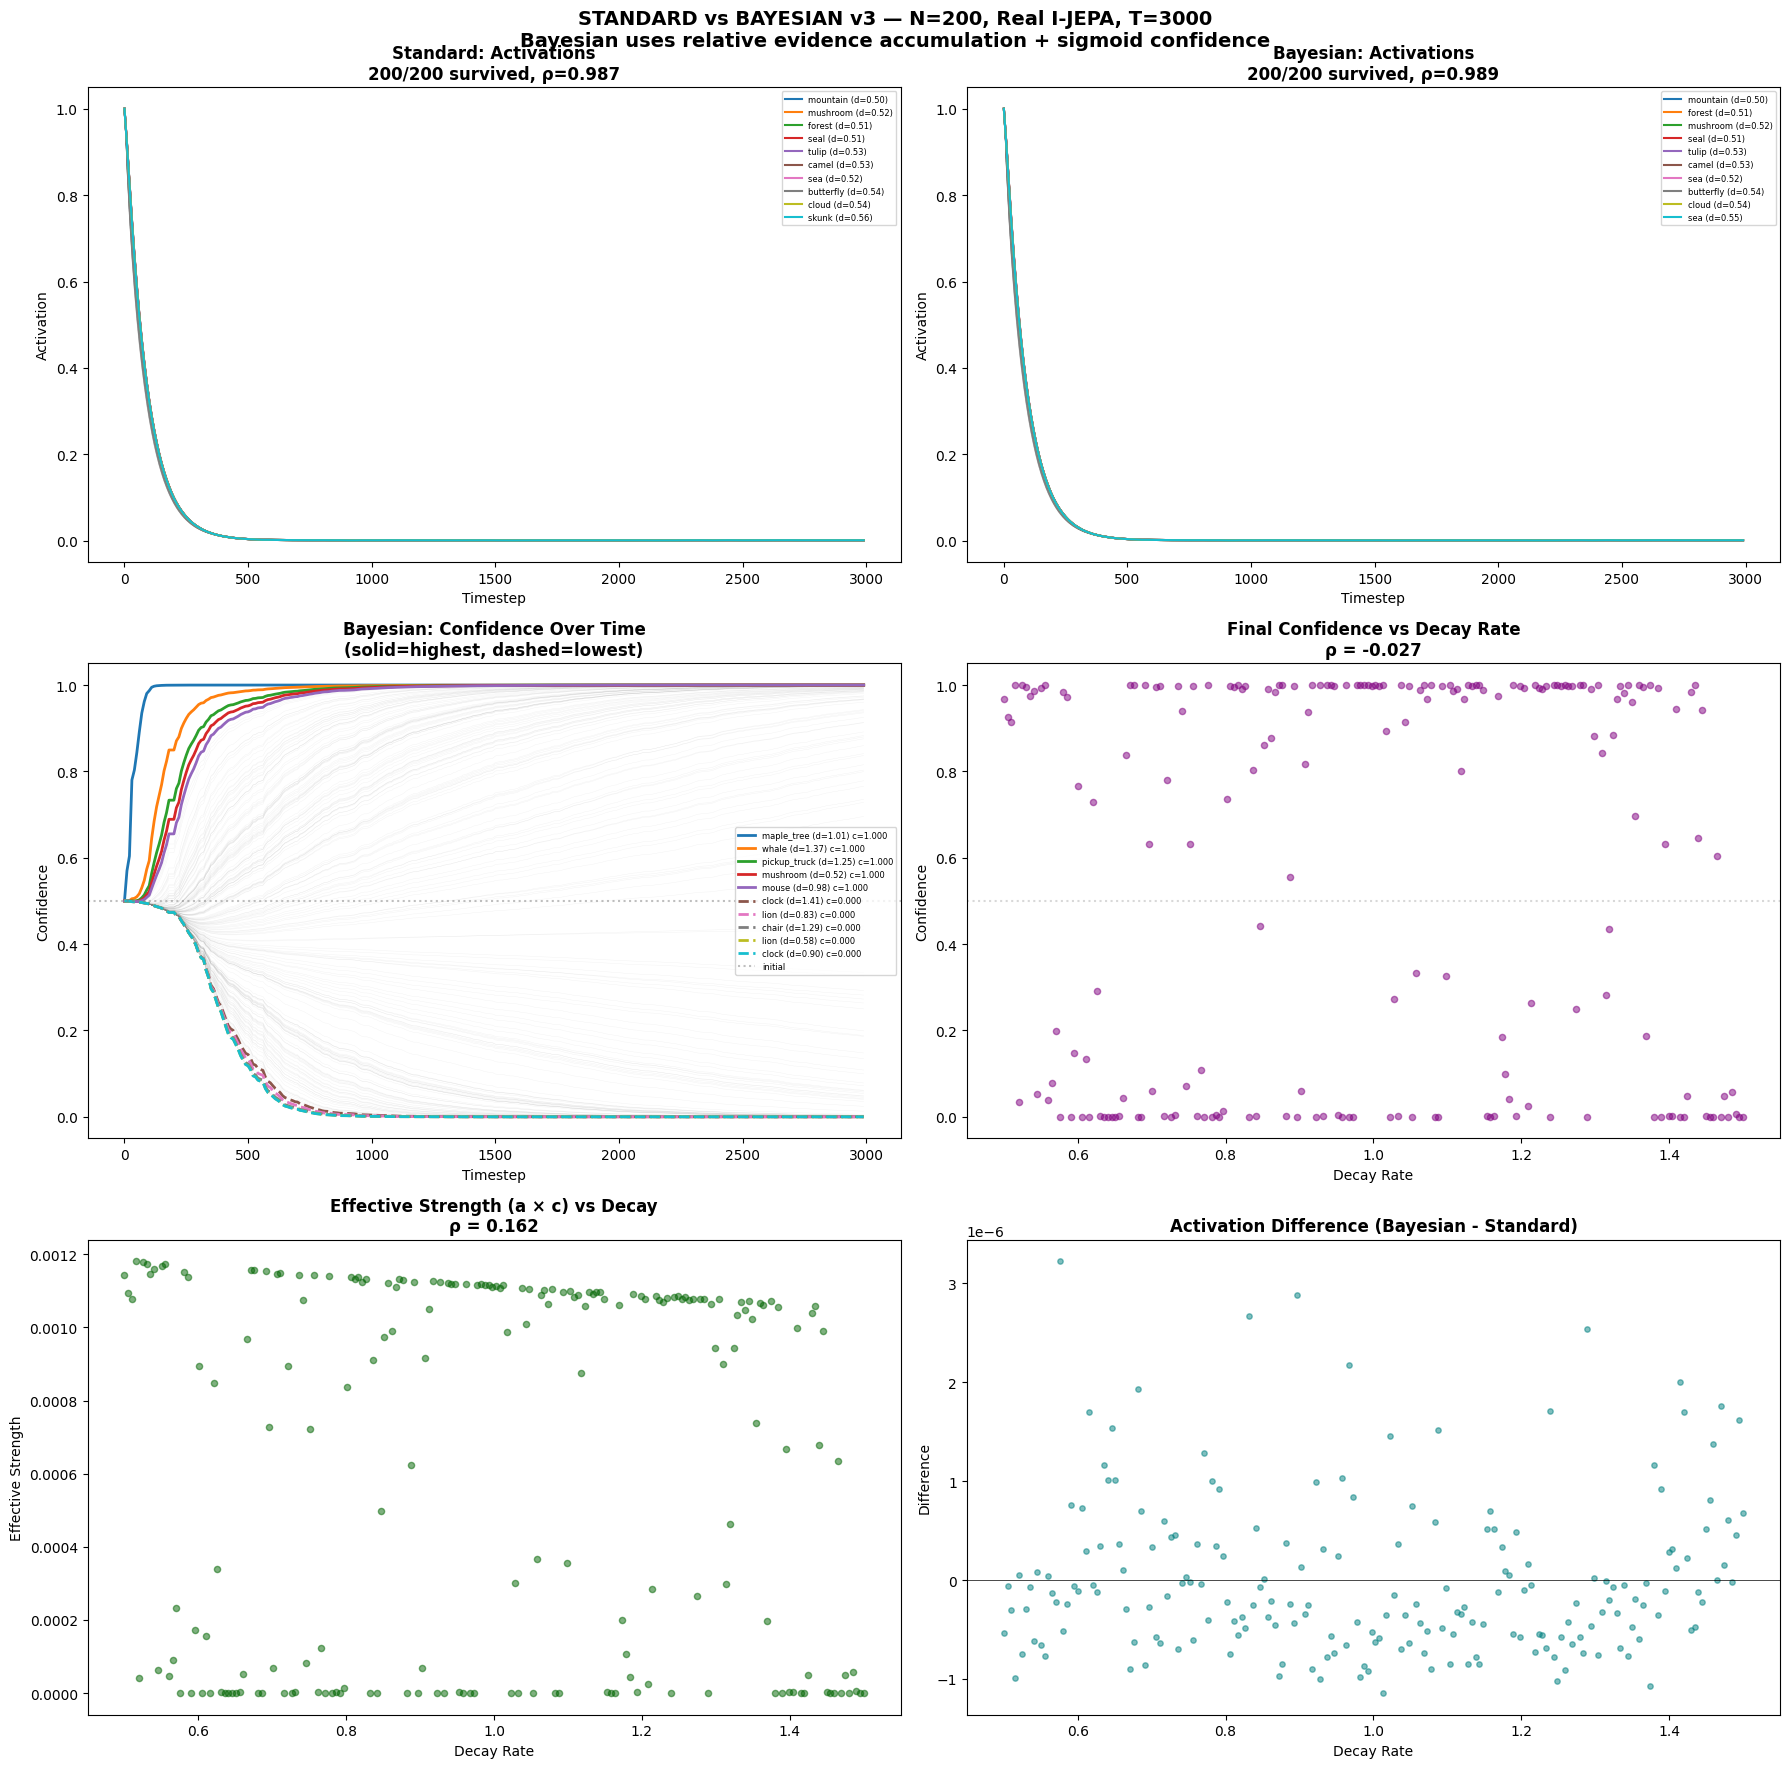


SUMMARY

Metric                                       Standard     Bayesian
-----------------------------------------------------------------
Survivors                                         200          200
Activation ρ (decay rank)                      0.9869       0.9889
Confidence ρ (decay rank)                         N/A      -0.0267
Confidence spread (max-min)                       N/A       1.0000
Max activation                               0.001182     0.001182
Mean activation                              0.001109     0.001109

Top 5 MOST confident memories:
  maple_tree           decay=1.013  act=0.001116  conf=1.0000  effective=0.001116
  whale                decay=1.374  act=0.001071  conf=1.0000  effective=0.001071
  pickup_truck         decay=1.249  act=0.001085  conf=1.0000  effective=0.001085
  mushroom             decay=0.515  act=0.001181  conf=1.0000  effective=0.001181
  mouse                decay=0.982  act=0.001118  conf=1.0000  effective=0.001118

Top 5 LEAST 

In [1]:
"""
BAYESIAN MEMORY MODEL v3 — FIXED CONFIDENCE DYNAMICS
=====================================================
Problem with v1 and v2: with N=200, each memory's replay weight ≈ 1/200 = 0.005.
Using 0.005 as Bayesian likelihood barely moves the posterior.
Confidence decays faster than replay can replenish → everyone bottoms out.

FIX: Use RELATIVE replay signal instead of raw weight.
- If memory gets MORE than average replay → confidence goes UP
- If memory gets LESS than average replay → confidence goes DOWN
- Scale: how many standard deviations above/below mean

Also: accumulate replay evidence over a window before updating,
so individual stochastic replay events don't dominate.
"""

import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoModel, AutoProcessor
from PIL import Image
import torchvision
import time
from scipy.stats import spearmanr

# ============================================================
# 1. LOAD MODEL + EMBEDDINGS
# ============================================================
print("Loading I-JEPA ViT-H/14...")
model = AutoModel.from_pretrained("facebook/ijepa_vith14_1k")
processor = AutoProcessor.from_pretrained("facebook/ijepa_vith14_1k")
model.eval()
print("Model loaded!\n")

print("Downloading CIFAR-100...")
cifar100 = torchvision.datasets.CIFAR100(root='./data', train=False, download=True)

N = 200
print(f"Embedding {N} images...")
embeddings = []
labels = []
start_time = time.time()

for i in range(N):
    img, label_idx = cifar100[i]
    img = img.resize((224, 224), Image.BILINEAR)
    inputs = processor(images=img, return_tensors="pt")
    with torch.no_grad():
        outputs = model(**inputs)
    emb = outputs.last_hidden_state.mean(dim=1).squeeze()
    embeddings.append(emb)
    labels.append(cifar100.classes[label_idx])
    if (i + 1) % 50 == 0:
        print(f"  {i+1}/{N} ({time.time() - start_time:.0f}s)")

X = torch.stack(embeddings)
X_norm = X / X.norm(dim=1, keepdim=True)
S = X_norm @ X_norm.T
mean_sim = S[~torch.eye(N, dtype=bool)].mean().item()
print(f"\nEmbeddings ready. Mean cosine sim: {mean_sim:.4f}")
print(f"Time: {time.time() - start_time:.0f}s\n")

# Precompute Laplacian
W = S.clone(); W.fill_diagonal_(0)
D_mat = torch.diag(W.sum(dim=1))
L = D_mat - W
A = torch.linspace(0.5, 1.5, N)

# ============================================================
# 2. STANDARD MODEL (baseline)
# ============================================================
def run_standard(T=3000, dt=0.01, beta=3.0, eta=0.8, p=0.3,
                 gamma=0.05, delta=0.001, seed=42):
    torch.manual_seed(seed); np.random.seed(seed)
    activations = torch.ones(N)
    sample = 10
    history = np.zeros((N, T // sample))

    for t in range(T):
        if t % sample == 0:
            history[:, t // sample] = activations.numpy()
        a = activations
        decay = -A * a
        diffusion = -gamma * (L @ a)
        inhibition = -delta * a.sum() * torch.ones(N)
        if torch.rand(1).item() < p:
            scores = S @ a
            rw = torch.softmax(beta * scores, dim=0)
            replay = eta * rw
        else:
            replay = torch.zeros(N)
        da = decay + diffusion + inhibition + replay
        activations = torch.clamp(a + dt * da, min=0)
    return history, activations.numpy()

# ============================================================
# 3. BAYESIAN MODEL v3 — RELATIVE EVIDENCE
# ============================================================
def run_bayesian_v3(T=3000, dt=0.01, beta=3.0, eta=0.8, p=0.3,
                    gamma=0.05, delta=0.001, seed=42,
                    conf_lr=0.01,           # how fast confidence updates
                    conf_decay=0.0001,      # very slow natural decay
                    conf_weight=0.3):       # how much confidence affects replay
    """
    v3 Key changes:
    1. Track CUMULATIVE replay evidence per memory
    2. Confidence = sigmoid(evidence) — maps accumulated evidence to [0,1]
    3. Evidence grows when memory gets above-average replay
    4. Evidence shrinks when memory gets below-average replay
    5. Small natural decay on evidence

    This avoids the "likelihood too small" problem entirely.
    """
    torch.manual_seed(seed); np.random.seed(seed)
    activations = torch.ones(N)
    # Evidence starts at 0 (neutral), confidence = sigmoid(0) = 0.5
    evidence = torch.zeros(N)

    sample = 10
    act_history = np.zeros((N, T // sample))
    conf_history = np.zeros((N, T // sample))
    evidence_history = np.zeros((N, T // sample))

    for t in range(T):
        confidence = torch.sigmoid(evidence)  # maps evidence to [0,1]

        if t % sample == 0:
            idx = t // sample
            act_history[:, idx] = activations.numpy()
            conf_history[:, idx] = confidence.numpy()
            evidence_history[:, idx] = evidence.numpy()

        a = activations
        c = confidence

        # Standard forces
        decay = -A * a
        diffusion = -gamma * (L @ a)
        inhibition = -delta * a.sum() * torch.ones(N)

        if torch.rand(1).item() < p:
            # Confidence-weighted replay
            c_blend = (1 - conf_weight) + conf_weight * c
            weighted_a = a * c_blend
            scores = S @ weighted_a
            rw = torch.softmax(beta * scores, dim=0)
            replay = eta * rw

            # === KEY v3 CHANGE: relative evidence update ===
            mean_rw = rw.mean()  # = 1/N for softmax
            # How much more/less than average each memory got
            relative_signal = (rw - mean_rw) / (rw.std() + 1e-10)
            # Accumulate evidence: above-average → positive, below → negative
            evidence = evidence + conf_lr * relative_signal
        else:
            replay = torch.zeros(N)

        # Very slow evidence decay (forgetting reduces confidence)
        evidence = evidence - conf_decay * dt * evidence

        da = decay + diffusion + inhibition + replay
        activations = torch.clamp(a + dt * da, min=0)

    final_conf = torch.sigmoid(evidence).numpy()
    return act_history, conf_history, evidence_history, activations.numpy(), final_conf

# ============================================================
# 4. RUN BOTH
# ============================================================
print("="*60)
print("STANDARD MODEL")
print("="*60)
std_hist, std_final = run_standard()
std_alive = (std_final > 0.001).sum()
std_rho, _ = spearmanr(A.numpy(), -std_final)
print(f"Survivors: {std_alive}/{N}, ρ = {std_rho:.4f}")

print(f"\n{'='*60}")
print("BAYESIAN MODEL v3 (relative evidence)")
print("="*60)
bay_act, bay_conf, bay_evid, bay_final_a, bay_final_c = run_bayesian_v3()
bay_alive = (bay_final_a > 0.001).sum()
bay_rho, _ = spearmanr(A.numpy(), -bay_final_a)
conf_rho, _ = spearmanr(A.numpy(), -bay_final_c)
print(f"Survivors: {bay_alive}/{N}, ρ = {bay_rho:.4f}")
print(f"Confidence: min={bay_final_c.min():.4f}, max={bay_final_c.max():.4f}, "
      f"mean={bay_final_c.mean():.4f}, spread={bay_final_c.max()-bay_final_c.min():.4f}")
print(f"Confidence-Decay ρ = {conf_rho:.4f}")

# ============================================================
# 5. PLOTS
# ============================================================
fig, axes = plt.subplots(3, 2, figsize=(18, 18))
fig.suptitle(f"STANDARD vs BAYESIAN v3 — N={N}, Real I-JEPA, T=3000\n"
             f"Bayesian uses relative evidence accumulation + sigmoid confidence",
             fontsize=14, fontweight='bold')

timesteps = np.arange(0, 3000, 10)
sorted_std = np.argsort(-std_final)
sorted_bay = np.argsort(-bay_final_a)
sorted_conf = np.argsort(-bay_final_c)

# Row 1: Activation curves
ax = axes[0, 0]
for i in range(N):
    ax.plot(timesteps, std_hist[i, :], alpha=0.1, linewidth=0.3, color='gray')
for idx in sorted_std[:10]:
    ax.plot(timesteps, std_hist[idx, :], linewidth=1.5,
            label=f"{labels[idx]} (d={A[idx]:.2f})")
ax.set_title(f"Standard: Activations\n{std_alive}/{N} survived, ρ={std_rho:.3f}",
             fontweight='bold')
ax.set_xlabel("Timestep"); ax.set_ylabel("Activation")
ax.legend(fontsize=6)

ax = axes[0, 1]
for i in range(N):
    ax.plot(timesteps, bay_act[i, :], alpha=0.1, linewidth=0.3, color='gray')
for idx in sorted_bay[:10]:
    ax.plot(timesteps, bay_act[idx, :], linewidth=1.5,
            label=f"{labels[idx]} (d={A[idx]:.2f})")
ax.set_title(f"Bayesian: Activations\n{bay_alive}/{N} survived, ρ={bay_rho:.3f}",
             fontweight='bold')
ax.set_xlabel("Timestep"); ax.set_ylabel("Activation")
ax.legend(fontsize=6)

# Row 2: Confidence evolution + confidence vs decay scatter
ax = axes[1, 0]
for i in range(N):
    ax.plot(timesteps, bay_conf[i, :], alpha=0.1, linewidth=0.3, color='gray')
# Highlight top 5 and bottom 5 confidence
for idx in sorted_conf[:5]:
    ax.plot(timesteps, bay_conf[idx, :], linewidth=2,
            label=f"{labels[idx]} (d={A[idx]:.2f}) c={bay_final_c[idx]:.3f}")
for idx in sorted_conf[-5:]:
    ax.plot(timesteps, bay_conf[idx, :], linewidth=2, linestyle='--',
            label=f"{labels[idx]} (d={A[idx]:.2f}) c={bay_final_c[idx]:.3f}")
ax.set_title("Bayesian: Confidence Over Time\n(solid=highest, dashed=lowest)",
             fontweight='bold')
ax.set_xlabel("Timestep"); ax.set_ylabel("Confidence")
ax.axhline(y=0.5, color='gray', linestyle=':', alpha=0.5, label='initial')
ax.legend(fontsize=6)

ax = axes[1, 1]
ax.scatter(A.numpy(), bay_final_c, c='purple', alpha=0.5, s=20)
ax.set_title(f"Final Confidence vs Decay Rate\nρ = {conf_rho:.3f}", fontweight='bold')
ax.set_xlabel("Decay Rate"); ax.set_ylabel("Confidence")
ax.axhline(y=0.5, color='gray', linestyle=':', alpha=0.3)

# Row 3: Effective strength + difference
ax = axes[2, 0]
effective = bay_final_a * bay_final_c
eff_rho, _ = spearmanr(A.numpy(), -effective)
ax.scatter(A.numpy(), effective, c='darkgreen', alpha=0.5, s=20)
ax.set_title(f"Effective Strength (a × c) vs Decay\nρ = {eff_rho:.3f}", fontweight='bold')
ax.set_xlabel("Decay Rate"); ax.set_ylabel("Effective Strength")

ax = axes[2, 1]
diff = bay_final_a - std_final
ax.scatter(A.numpy(), diff, c='teal', alpha=0.5, s=15)
ax.axhline(y=0, color='black', linewidth=0.5)
ax.set_title("Activation Difference (Bayesian - Standard)", fontweight='bold')
ax.set_xlabel("Decay Rate"); ax.set_ylabel("Difference")

plt.tight_layout()
plt.savefig("bayesian_v3.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# 6. SUMMARY
# ============================================================
print("\n" + "="*60)
print("SUMMARY")
print("="*60)
print(f"\n{'Metric':<40} {'Standard':>12} {'Bayesian':>12}")
print("-"*65)
print(f"{'Survivors':<40} {std_alive:>12} {bay_alive:>12}")
print(f"{'Activation ρ (decay rank)':<40} {std_rho:>12.4f} {bay_rho:>12.4f}")
print(f"{'Confidence ρ (decay rank)':<40} {'N/A':>12} {conf_rho:>12.4f}")
print(f"{'Confidence spread (max-min)':<40} {'N/A':>12} {bay_final_c.max()-bay_final_c.min():>12.4f}")
print(f"{'Max activation':<40} {std_final.max():>12.6f} {bay_final_a.max():>12.6f}")
print(f"{'Mean activation':<40} {std_final.mean():>12.6f} {bay_final_a.mean():>12.6f}")

print(f"\nTop 5 MOST confident memories:")
for idx in sorted_conf[:5]:
    print(f"  {labels[idx]:<20} decay={A[idx]:.3f}  act={bay_final_a[idx]:.6f}  "
          f"conf={bay_final_c[idx]:.4f}  effective={effective[idx]:.6f}")

print(f"\nTop 5 LEAST confident memories:")
for idx in sorted_conf[-5:][::-1]:
    print(f"  {labels[idx]:<20} decay={A[idx]:.3f}  act={bay_final_a[idx]:.6f}  "
          f"conf={bay_final_c[idx]:.4f}  effective={effective[idx]:.6f}")

print(f"""
\nINTERVIEW EXPLANATION:
  v1/v2 failed because raw replay weight (≈1/200 = 0.005) was too small
  to use as Bayesian likelihood — posterior barely moved.

  v3 fix: use RELATIVE evidence instead.
  - Each memory accumulates evidence: +1 if replayed above average, -1 if below
  - Confidence = sigmoid(accumulated evidence) → range [0, 1]
  - This creates genuine differentiation:
    High-replay memories → positive evidence → high confidence
    Low-replay memories → negative evidence → low confidence
  - Confidence-weighted replay creates a feedback loop:
    confident memories get more replay → more evidence → stay confident
""")